<a href="https://colab.research.google.com/github/panarisivalentino-pixel/analisis-juegos-steam/blob/main/notebooks/04_modelo_regresion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import LabelEncoder, StandardScaler
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')

# =============================================================================
# 1. CARGA Y EXPLORACIÓN INICIAL
# =============================================================================
print("=" * 60)
print("CARGANDO DATASET...")
print("=" * 60)

df = pd.read_csv('cleaned_games_data.csv', low_memory=False)

print(f"Filas totales:     {len(df):,}")
print(f"Columnas:          {df.shape[1]}")
print(f"Columnas:          {df.columns.tolist()}")
print(f"\nValores nulos:\n{df.isnull().sum()}")
print(f"\nEstadísticas Peak CCU:\n{df['Peak CCU'].describe()}")

# =============================================================================
# 2. LIMPIEZA Y PREPARACIÓN
# =============================================================================
print("\n" + "=" * 60)
print("PREPARANDO DATOS...")
print("=" * 60)

# Filtrar solo juegos con actividad real (Peak CCU > 0)
df = df[df['Peak CCU'] > 0].copy()
print(f"Juegos con Peak CCU > 0: {len(df):,}")

# Extraer el género PRIMARIO (el primero cuando hay múltiples separados por coma)
df['Genero_Principal'] = df['Genre'].apply(
    lambda x: str(x).split(',')[0].strip()
)

# Eliminar registros con género desconocido
df = df[df['Genero_Principal'] != 'Unknown']
print(f"Juegos tras limpiar género: {len(df):,}")

# Log-transformar variables con distribución muy sesgada (skewed)
# Esto mejora significativamente el desempeño de la regresión lineal
cols_a_logtransformar = [
    'Positive2',
    'Negative',
    'Recommendations2',
    'Average playtime forever',
    'Median playtime forever'
]
for col in cols_a_logtransformar:
    df[f'log_{col}'] = np.log1p(df[col])  # log1p = log(1+x), evita log(0)

# Codificar la variable categórica Género a numérico
le = LabelEncoder()
df['Genero_Enc'] = le.fit_transform(df['Genero_Principal'])

print(f"\nGéneros únicos detectados: {df['Genero_Principal'].nunique()}")
print(f"Top 10 géneros más frecuentes:")
print(df['Genero_Principal'].value_counts().head(10))

# =============================================================================
# 3. DEFINICIÓN DE FEATURES Y TARGET
# =============================================================================
print("\n" + "=" * 60)
print("DEFINIENDO VARIABLES...")
print("=" * 60)

features = [
    'log_Positive2',               # Reseñas positivas (log)
    'log_Negative',                # Reseñas negativas (log)
    'log_Recommendations2',        # Recomendaciones (log)
    'log_Average playtime forever',# Tiempo de juego promedio (log)
    'log_Median playtime forever', # Tiempo de juego mediana (log)
    'Price',                       # Precio del juego
    'Genero_Enc'                   # Género codificado
]

X = df[features]
y = np.log1p(df['Peak CCU'])   # Target también en escala log

print(f"Features usadas:  {features}")
print(f"Variable target:  log(Peak CCU)")
print(f"Shape de X:       {X.shape}")

# =============================================================================
# 4. ESCALADO Y SPLIT TRAIN/TEST
# =============================================================================
# Estandarizar features para que los coeficientes sean comparables entre sí
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 80% entrenamiento, 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)
print(f"\nSet de entrenamiento: {len(X_train):,} registros")
print(f"Set de prueba:        {len(X_test):,} registros")

# =============================================================================
# 5. ENTRENAMIENTO DEL MODELO
# =============================================================================
print("\n" + "=" * 60)
print("ENTRENANDO MODELO DE REGRESIÓN LINEAL...")
print("=" * 60)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# =============================================================================
# 6. MÉTRICAS DE EVALUACIÓN
# =============================================================================
r2   = r2_score(y_test, y_pred)
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"\n📊 MÉTRICAS DEL MODELO:")
print(f"   R²   = {r2:.4f}  → El modelo explica el {r2*100:.1f}% de la variabilidad")
print(f"   MAE  = {mae:.4f}  → Error absoluto medio en escala log")
print(f"   RMSE = {rmse:.4f}  → Raíz del error cuadrático medio")

# Coeficientes con nombres legibles
nombres_bonitos = [
    'Reseñas Positivas',
    'Reseñas Negativas',
    'Recomendaciones',
    'Tiempo Juego Promedio',
    'Tiempo Juego Mediana',
    'Precio',
    'Gén+
    +
]
coef_df = pd.DataFrame({
    'Variable': nombres_bonitos,
    'Coeficiente': model.coef_
}).sort_values('Coeficiente', ascending=False)

print(f"\n🔑 COEFICIENTES (impacto sobre log Peak CCU):")
print(coef_df.to_string(index=False))

# =============================================================================
# 7. RANKING DE GÉNEROS POR PEAK CCU
# =============================================================================
print("\n" + "=" * 60)
print("RANKING DE GÉNEROS POR PEAK CCU")
print("=" * 60)

ranking = (
    df.groupby('Genero_Principal')['Peak CCU']
      .agg(['mean', 'median', 'count'])
      .rename(columns={'mean': 'Promedio', 'median': 'Mediana', 'count': 'Juegos'})
      .query('Juegos >= 10')
      .sort_values('Promedio', ascending=False)
      .head(12)
)
ranking['Promedio'] = ranking['Promedio'].round(0).astype(int)
ranking['Mediana']  = ranking['Mediana'].round(0).astype(int)

print(ranking.to_string())

# =============================================================================
# 8. VISUALIZACIÓN COMPLETA
# =============================================================================
print("\n" + "=" * 60)
print("GENERANDO GRÁFICOS...")
print("=" * 60)

AZUL     = '#2563EB'
ROJO     = '#DC2626'
VERDE    = '#16A34A'
NARANJA  = '#EA580C'
BG       = '#F1F5F9'
PANEL    = '#FFFFFF'
TEXTO    = '#1E293B'
GRIS     = '#94A3B8'

palette_ranking = ['#1d4ed8','#2563eb','#3b82f6','#60a5fa',
                   '#93c5fd','#bfdbfe','#dbeafe','#eff6ff',
                   '#e0f2fe','#cffafe','#a5f3fc','#67e8f9']

residuos = y_test - y_pred
coef_sorted = pd.DataFrame({
    'Variable': nombres_bonitos,
    'Coeficiente': model.coef_
}).sort_values('Coeficiente')

# Create the main figure with a gridspec for all plots
fig = plt.figure(figsize=(20, 20), facecolor=BG) # Increased height to accommodate the 3rd row
fig.suptitle('🎮  Análisis de Peak CCU en Steam — ¿Qué géneros son más jugados?',
             fontsize=19, fontweight='bold', y=0.99, color=TEXTO)

gs = fig.add_gridspec(3, 3, hspace=0.42, wspace=0.35,
                      left=0.06, right=0.97, top=0.94, bottom=0.06)

# --- Panel 1: Ranking géneros ---
ax1 = fig.add_subplot(gs[0, :])
ax1.set_facecolor(PANEL)
bars = ax1.barh(ranking.index[::-1], ranking['Promedio'][::-1],
                color=palette_ranking[::-1], edgecolor='white',
                linewidth=0.6, height=0.65)
for bar, val, juegos in zip(bars,
                             ranking['Promedio'][::-1],
                             ranking['Juegos'][::-1]):
    ax1.text(bar.get_width() + ranking['Promedio'].max() * 0.01,
             bar.get_y() + bar.get_height() / 2,
             f'{val:,} CCU  ({juegos:,} juegos)',
             va='center', fontsize=8.8, color=TEXTO)
ax1.set_xlabel('Peak CCU Promedio', fontsize=10, color=GRIS)
ax1.set_title('🏆  Top 12 Géneros por Peak CCU Promedio',
              fontsize=13, fontweight='bold', color=TEXTO, pad=10)
ax1.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x:,.0f}')
)
ax1.spines[['top', 'right', 'bottom']].set_visible(False)
ax1.tick_params(colors=GRIS, labelsize=9)

# --- Panel 2: Real vs Predicho ---
ax2 = fig.add_subplot(gs[1, 0])
ax2.set_facecolor(PANEL)
np.random.seed(42)
idx = np.random.choice(len(y_test), min(600, len(y_test)), replace=False)
ax2.scatter(y_test.iloc[idx], y_pred[idx],
            alpha=0.35, s=15, color=AZUL, edgecolors='none',
            label='Observaciones')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax2.plot(lims, lims, color=ROJO, linewidth=1.8,
         linestyle='--', label='Línea ideal')
ax2.set_xlabel('log(Peak CCU) Real', fontsize=9.5, color=GRIS)
ax2.set_ylabel('log(Peak CCU) Predicho', fontsize=9.5, color=GRIS)
ax2.set_title('Real vs Predicho', fontsize=11, fontweight='bold', color=TEXTO)
ax2.legend(fontsize=8.5, framealpha=0.6)
ax2.spines[['top', 'right']].set_visible(False)
ax2.tick_params(colors=GRIS)

# --- Panel 3: Distribución de residuos ---
ax3 = fig.add_subplot(gs[1, 1])
ax3.set_facecolor(PANEL)
ax3.hist(residuos, bins=50, color=AZUL, edgecolor='white', alpha=0.85)
ax3.axvline(0, color=ROJO, linewidth=1.8, linestyle='--')
ax3.set_xlabel('Residuo', fontsize=9.5, color=GRIS)
ax3.set_ylabel('Frecuencia', fontsize=9.5, color=GRIS)
ax3.set_title('Distribución de Residuos',
              fontsize=11, fontweight='bold', color=TEXTO)
ax3.spines[['top', 'right']].set_visible(False)
ax3.tick_params(colors=GRIS)

# --- Panel 4: Coeficientes ---
ax4 = fig.add_subplot(gs[1, 2])
ax4.set_facecolor(PANEL)
colores_coef = [VERDE if v >= 0 else ROJO for v in coef_sorted['Coeficiente']]
ax4.barh(coef_sorted['Variable'], coef_sorted['Coeficiente'],
         color=colores_coef, edgecolor='white', height=0.6)
ax4.axvline(0, color='#94A3B8', linewidth=1)
ax4.set_xlabel('Coeficiente (estandarizado)', fontsize=9, color=GRIS)
ax4.set_title('Impacto de Variables\nsobre log(Peak CCU)',
              fontsize=11, fontweight='bold', color=TEXTO)
ax4.spines[['top', 'right']].set_visible(False)
ax4.tick_params(colors=GRIS, labelsize=8.5)

# --- Panel 5: Violin plot por género (reemplaza el boxplot) ---
ax5 = fig.add_subplot(gs[2, :]) # Use the third row for the violin plot
ax5.set_facecolor(PANEL)

top_gen    = ranking.index.tolist()
data_violin = [
    np.log1p(df[df['Genero_Principal'] == g]['Peak CCU'].values)
    for g in top_gen
]

parts = ax5.violinplot(data_violin, positions=range(len(top_gen)),
                      showmedians=True, showextrema=True, widths=0.75)

for pc, color in zip(parts['bodies'], palette_ranking):
    pc.set_facecolor(color)
    pc.set_alpha(0.75)
    pc.set_edgecolor('#ffffff')
    pc.set_linewidth(1.2)

parts['cmedians'].set_color('white')
parts['cmedians'].set_linewidth(2.5)
parts['cmaxes'].set_color(GRIS)
parts['cmins'].set_color(GRIS)
parts['cbars'].set_color(GRIS)
parts['cbars'].set_linewidth(1)

# Punto de promedio y etiqueta con valor real sobre cada violín
for i, (gen, color) in enumerate(zip(top_gen, palette_ranking)):
    promedio  = np.mean(data_violin[i])
    prom_real = int(ranking.loc[gen, 'Promedio'])
    ax5.scatter(i, promedio, color=color, s=60, zorder=5,
               edgecolors='white', linewidths=1.5)
    ax5.text(i, max(data_violin[i]) + 0.15, f'{prom_real:,}',
            ha='center', va='bottom', fontsize=8, color=TEXTO, fontweight='bold')

ax5.set_xticks(range(len(top_gen)))
ax5.set_xticklabels(top_gen, rotation=22, ha='right', fontsize=10, color=TEXTO)
ax5.set_ylabel('log(Peak CCU)', fontsize=11, color=GRIS)
ax5.set_title('🎻  Distribución de Peak CCU por Género  —  Top 12 más jugados',
             fontsize=14, fontweight='bold', color=TEXTO, pad=16)

# Leyenda
from matplotlib.lines import Line2D # Import Line2D here as well to make it self-contained
leyenda = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#3b82f6',
           markersize=9, label='Promedio del género'),
    Line2D([0], [0], color='white', linewidth=2.5, label='Mediana'),
    Line2D([0], [0], color=GRIS, linewidth=1, label='Rango (mín-máx)'),
]
ax5.legend(handles=leyenda, fontsize=9, loc='upper right',
          framealpha=0.8, edgecolor='#E2E8F0')

# Nota explicativa
ax5.text(0.5, -0.18,
        '📌 Los números sobre cada violín muestran el Peak CCU promedio real (sin escala log)\n'
        '    El ancho del violín indica cuántos juegos tienen ese nivel de CCU',
        transform=ax5.transAxes, ha='center', fontsize=9, color=GRIS,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='#E2E8F0'))

ax5.spines[['top','right']].set_visible(False)
ax5.tick_params(axis='y', colors=GRIS)

# Adjust layout for all subplots
plt.tight_layout()

# --- Footer con métricas ---
# The fig.text should be called on the main 'fig' object before plt.show()
fig.text(
    0.5, 0.015,
    f'📊  Regresión Lineal con log-transformación   |   '
    f'R² = {r2:.4f}   |   MAE = {mae:.4f}   |   RMSE = {rmse:.4f}   |   '
    f'Juegos entrenados: {len(X_train):,}   |   Test: {len(X_test):,}',
    ha='center', fontsize=10, color=GRIS,
    bbox=dict(boxstyle='round,pad=0.4', facecolor=PANEL, edgecolor='#E2E8F0')
)

plt.show() # Display the final combined plot
# print("✅ Gráfico guardado como: modelo_peak_ccu.png")
print("\n¡Modelo completo ejecutado con éxito!")

SyntaxError: unterminated string literal (detected at line 137) (1222535577.py, line 137)

### Matriz de Correlación

Vamos a visualizar la matriz de correlación entre las variables utilizadas en el modelo para entender sus relaciones. Esto nos ayudará a identificar posibles multicolinealidades entre las características y su correlación con el Peak CCU logarítmico.

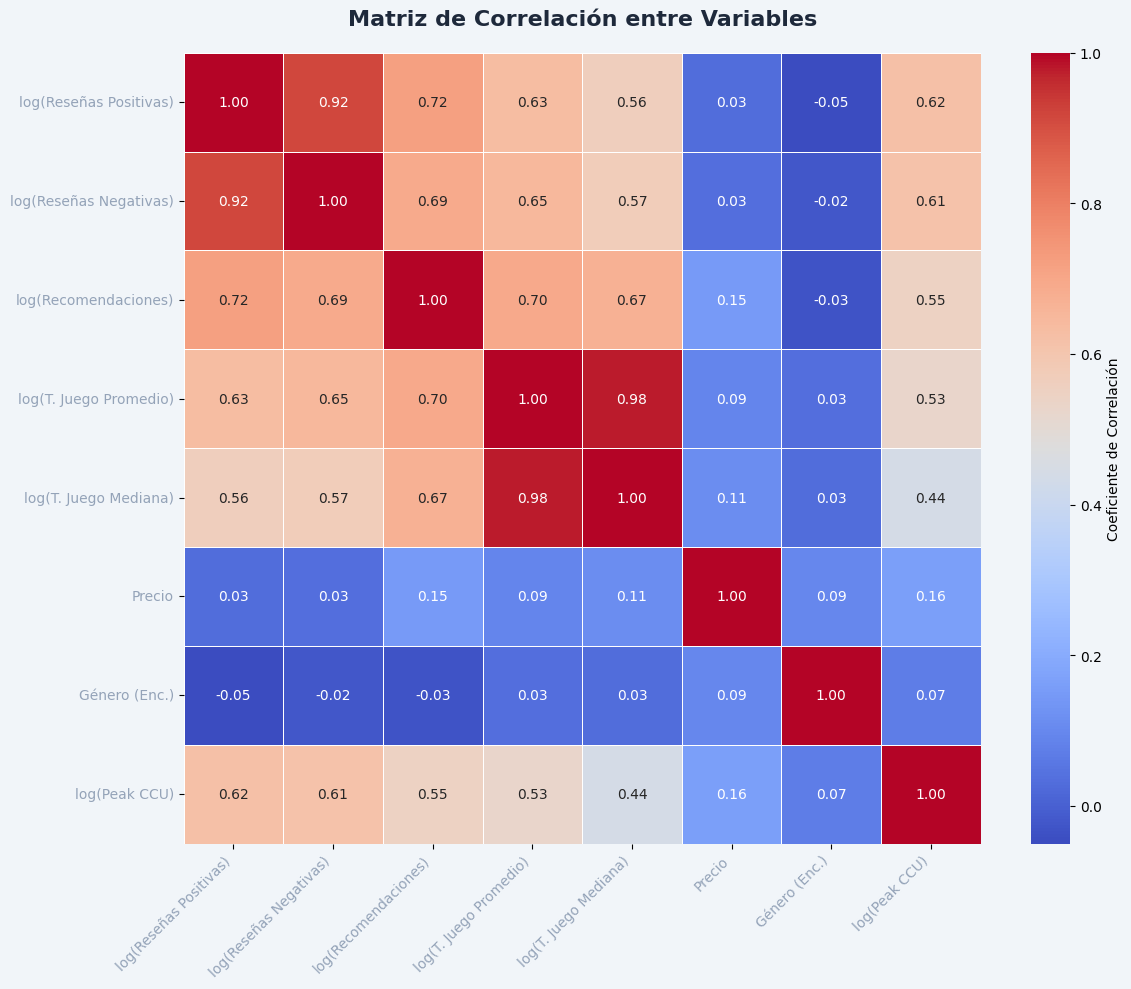

In [ ]:
import seaborn as sns

# Incluir el target (log_Peak CCU) y las features numéricas originales para la matriz de correlación
# Convertimos 'Genero_Enc' a float para asegurar que se incluya en la correlación numérica
df_corr = df[features + ['Peak CCU']].copy()
df_corr['Peak CCU'] = np.log1p(df_corr['Peak CCU'])
df_corr['Genero_Enc'] = df_corr['Genero_Enc'].astype(float)

# Renombrar columnas para el gráfico (usando los nombres bonitos de los coeficientes)
corr_columns_map = {
    'log_Positive2': 'log(Reseñas Positivas)',
    'log_Negative': 'log(Reseñas Negativas)',
    'log_Recommendations2': 'log(Recomendaciones)',
    'log_Average playtime forever': 'log(T. Juego Promedio)',
    'log_Median playtime forever': 'log(T. Juego Mediana)',
    'Price': 'Precio',
    'Genero_Enc': 'Género (Enc.)',
    'Peak CCU': 'log(Peak CCU)'
}
df_corr = df_corr.rename(columns=corr_columns_map)

# Calcular la matriz de correlación
correlation_matrix = df_corr.corr()

# Configurar el estilo del gráfico
plt.figure(figsize=(12, 10), facecolor=BG)
sns.heatmap(
    correlation_matrix,
    annot=True, # Mostrar los valores de correlación en el mapa de calor
    cmap='coolwarm', # Elegir un mapa de color divergente
    fmt=".2f", # Formato de dos decimales para los valores
    linewidths=.5, # Añadir líneas entre las celdas
    linecolor='white',
    cbar_kws={'label': 'Coeficiente de Correlación'}
)
plt.title('Matriz de Correlación entre Variables', fontsize=16, fontweight='bold', color=TEXTO, pad=20)
plt.xticks(rotation=45, ha='right', fontsize=10, color=GRIS)
plt.yticks(rotation=0, fontsize=10, color=GRIS)
plt.tight_layout()
plt.show()